<a href="https://colab.research.google.com/github/RohitRevankarDev/AML-Assignment-261100610035/blob/main/1c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)


In [ ]:

data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target
df = data.frame

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:", df.isnull().sum().sum())

print("\nTarget classes:")
print(dict(enumerate(data.target_names)))

print("\nClass distribution:")
print(y.value_counts().sort_index())


Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Missing values: 0

Target classes:
{0: np.str_('malignant'), 1: np.str_('benign')}

Class distribution:
target
0    212
1    357
Name: count, dtype: int64


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 455
Testing samples: 114


In [ ]:

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    "L1 Regularization": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l1", solver="liblinear",
            max_iter=5000, random_state=42
        ))
    ]),
    "L2 Regularization": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l2", max_iter=5000, random_state=42
        ))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9825,0.9825,0.9825,0.9825
1,L1 Regularization,0.9912,0.9913,0.9912,0.9912
2,L2 Regularization,0.9825,0.9825,0.9825,0.9825



 Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



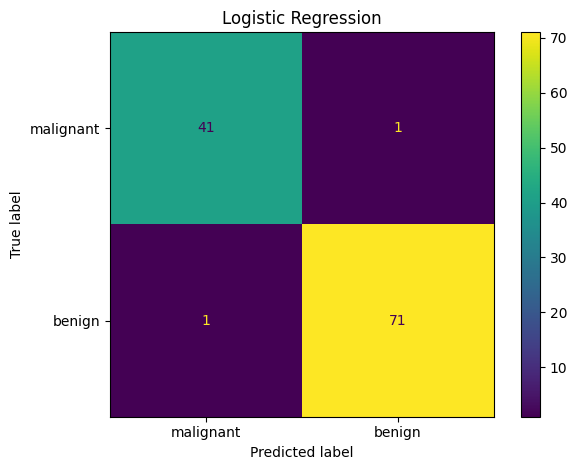


 L1 Regularization
              precision    recall  f1-score   support

   malignant       1.00      0.98      0.99        42
      benign       0.99      1.00      0.99        72

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



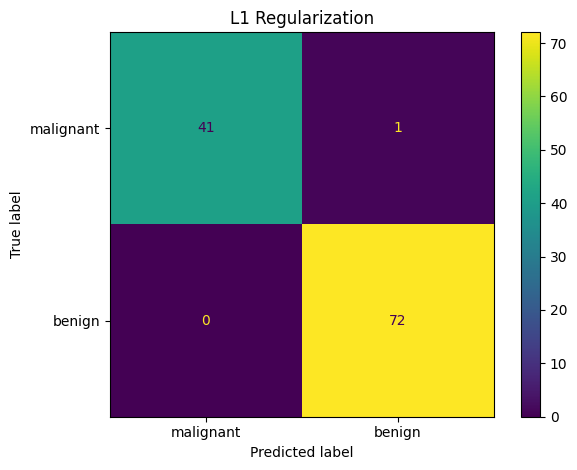


 L2 Regularization
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



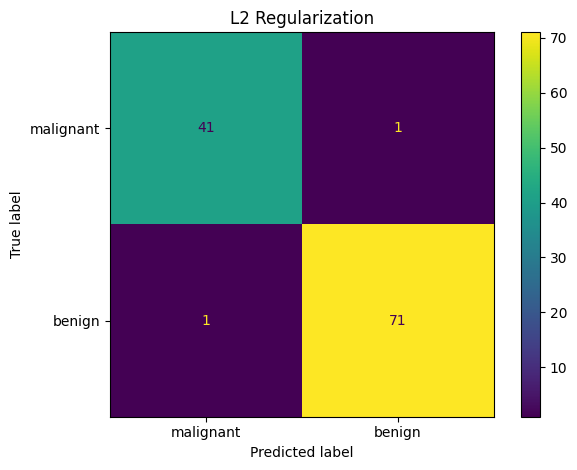

In [ ]:

for name, model in models.items():
    pred = model.predict(X_test)

    print("\n", name)
    print(classification_report(
        y_test,
        pred,
        target_names=data.target_names,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        display_labels=data.target_names
    )

    plt.title(name)
    plt.tight_layout()
    plt.show()


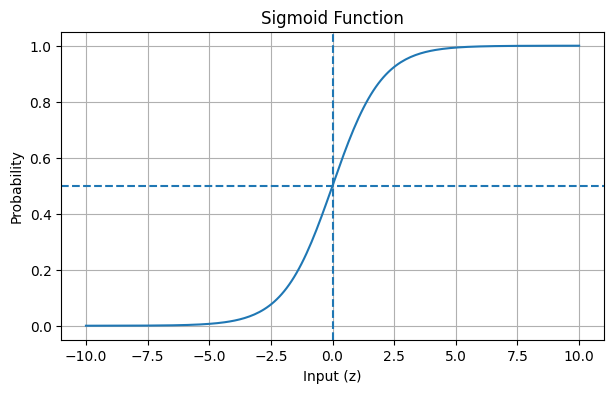

Sigmoid(0): 0.5


In [ ]:

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 200)

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid(True)
plt.show()

print("Sigmoid(0):", sigmoid(0))


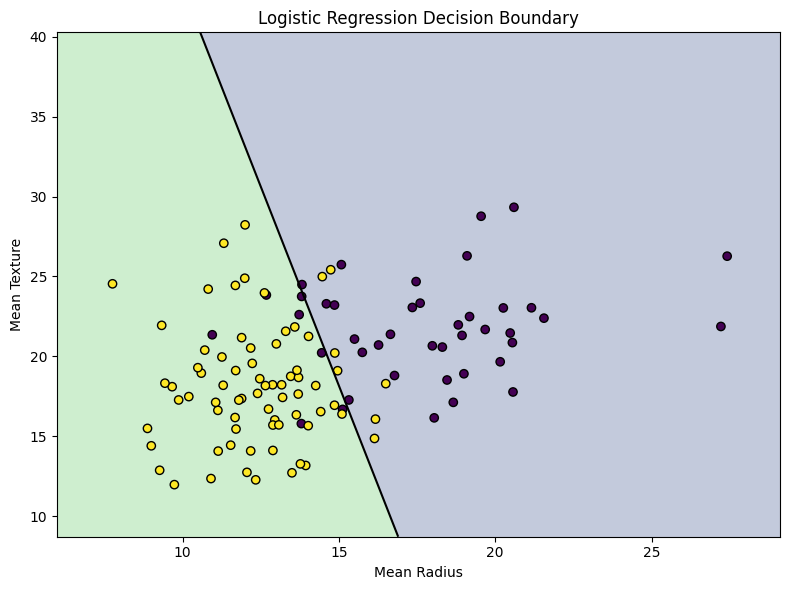

In [ ]:

X2 = data.data[["mean radius", "mean texture"]]
y2 = data.target

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2,
    test_size=0.2,
    random_state=42,
    stratify=y2
)

boundary_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

boundary_model.fit(X2_train, y2_train)

x_min, x_max = X2["mean radius"].min() - 1, X2["mean radius"].max() + 1
y_min, y_max = X2["mean texture"].min() - 1, X2["mean texture"].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = pd.DataFrame({
    "mean radius": xx.ravel(),
    "mean texture": yy.ravel()
})

prob = boundary_model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, prob, levels=[0, 0.5, 1], alpha=0.3)
plt.contour(xx, yy, prob, levels=[0.5], colors="black")
plt.scatter(
    X2_test["mean radius"],
    X2_test["mean texture"],
    c=y2_test,
    edgecolors="black"
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.tight_layout()
plt.show()


In [ ]:

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=5, scoring="accuracy"
    )

    print(name)
    print("Fold accuracies:", np.round(scores, 4))
    print("Mean accuracy:", round(scores.mean(), 4))
    print()


Logistic Regression
Fold accuracies: [0.967 0.978 0.967 1.    0.989]
Mean accuracy: 0.9802

L1 Regularization
Fold accuracies: [0.956 0.978 0.967 0.989 0.989]
Mean accuracy: 0.9758

L2 Regularization
Fold accuracies: [0.967 0.978 0.967 1.    0.989]
Mean accuracy: 0.9802




### Result

Logistic Regression was implemented using the Breast Cancer dataset. L1 and L2 regularization were applied and compared with standard Logistic Regression. The models were evaluated using accuracy, precision, recall and F1-score. Confusion matrices, the sigmoid function and the decision boundary were visualized, and five-fold cross-validation was performed.

### Conclusion

The experiment demonstrates Logistic Regression for binary classification and the effect of regularization on model performance. Evaluation metrics and cross-validation provide a basis for comparing the models.
